# 02 · Modeling: which helper, which cut-off, and how good is it really?

Five helpers race in two settings, graded with the rules fixed in Step 6:

1. Which helper ranks buyers best, before the call and after it?
2. Is the winner really better, or just lucky on these folds?
3. Where should the yes/no cut-off be, and does accuracy then reach the brief's 81%?
4. What does the call list achieve (gains), and are its probabilities right?
5. Does it still work on later months it has never seen?

The whole notebook takes about 5–8 minutes to run.

## 0. Framing: the reasoning behind this notebook

### Why two models: before the call and after it

A prediction is only useful if every input is known **at the moment the decision is made**. The
bank makes two decisions, at two different moments:

1. **Before dialling:** whom to call, and in what order. Known: who the customer is (age, job,
   balance, loans, ...), the date, and how often we already called them. **Not known: how long the
   call will last.**
2. **After a conversation:** is this customer worth calling back? Now the call's length is known.

`duration` is the strongest signal in the data (buyers' calls last 629 s at the median vs 164 s,
notebook 01). A single model trained with it would look excellent, but it could never be used
before a call: the number does not exist yet, and filling it with 0 or an average gives
nonsense. Using information from the future like this is called **data leakage**. Dropping
`duration` everywhere would waste it, because it really helps the second decision. So we build
**one model per decision**, each using exactly what is known at that moment.

Two cautions:

- Long calls don't *cause* sales; interested customers talk longer. "Make calls longer" is not a
  recommendation.
- `duration` is the length of the **last** call, which is often the call where the customer said
  yes. The after-call scores are therefore a best case; in real use the model ranks customers
  whose conversation ended without a sale yet.

### Why these five helpers

The data has 40,000 rows, a mix of numbers and categories, and only 7% yes; the client wants
explanations and trustworthy probabilities. So we test a ladder from simple to flexible, where
each step adds one ability:

| Helper | What it adds | Why it suits this data |
| --- | --- | --- |
| Baseline (always "no") | Nothing | The yardstick every model must beat |
| Logistic regression | A weight per fact | Fast, explainable, honest probabilities; the standard reference on tables |
| Decision tree | If-then rules, interactions, U-shapes such as age | Rules a person can read and follow |
| Random forest | Hundreds of trees voting | Steadier than one tree, little tuning needed |
| Gradient boosting | Trees that correct each other's mistakes | Usually the strongest on tables; fast on 40,000 rows |

Not tested, and why: k-nearest neighbours and support vector machines (slow on 40,000 rows and
hard to explain), neural networks (no advantage on a small table, hardest to explain),
XGBoost/LightGBM/CatBoost (the same idea as gradient boosting, so an extra dependency for little
gain), and Naive Bayes (assumes the facts are independent, but age and job are not).

### Which score for which use

Each way of using the model asks a different question, so it needs a different score. Accuracy
answers none of them here.

| Use | Question | Score |
| --- | --- | --- |
| Compare models fairly | Who ranks buyers above non-buyers best, whatever the cut-off? | **PR-AUC** (main), ROC-AUC |
| Fixed call capacity ("4,000 calls this week") | What do the top 4,000 calls achieve? | **Gains, success rate and lift** of the top of the list |
| Calls are costly, or customers get annoyed | Of the calls made, how many succeed? | **Precision** |
| Each sale is valuable and calls are cheap | Of all buyers, how many do we reach? | **Recall** |
| Costs not known yet | A fair balance of the two | **F1**, used for our cut-off |
| Forecast the campaign ("how many sales will 10,000 calls bring?") | Are the probabilities right? | **Calibration**: predicted vs actual buyers |
| Will it hold for the next campaign? | The same scores on later months | **Time check** (section 5) |
| The brief | Share of right answers | Accuracy: reported, but always "no" scores 92.8% |

If the bank shares the cost of a call and the profit from a sale, the cut-off should maximise
expected profit instead of F1, by changing `THRESHOLD_METRIC` in `models.py`.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import PercentFormatter
from sklearn.metrics import average_precision_score, roc_auc_score

from term_deposit.config import FIGURES_DIR, FINAL_MODEL, STAGES, TARGET
from term_deposit.data import load_data
from term_deposit.evaluation import (
    MAIN_METRIC,
    corrected_ttest,
    cv_scores,
    gains_table,
    out_of_fold_scores,
    summarize,
    time_ordered_split,
)
from term_deposit.models import get_candidates, with_threshold

pd.set_option("display.precision", 3)

BLUE, ORANGE, MUTED = "#2a78d6", "#eb6834", "#898781"
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "savefig.dpi": 150,
        "savefig.bbox": "tight",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.edgecolor": "#c3c2b7",
        "axes.grid": True,
        "axes.axisbelow": True,
        "grid.color": "#e1e0d9",
        "grid.linewidth": 0.6,
        "axes.labelcolor": "#52514e",
        "xtick.color": "#52514e",
        "ytick.color": "#52514e",
        "axes.titlesize": 11,
        "axes.titleweight": "bold",
    }
)
STAGE_NAMES = {"pre_call": "Before the call", "post_call": "After the call"}

df = load_data()
y = df[TARGET]
candidates = get_candidates()

## 1. The race: five helpers, two settings

- **Before the call** (`pre_call`, 12 columns, no `duration`): whom to call, and in what order.
- **After the call** (`post_call`, all 13 columns): whom to call back.

Each helper tunes its settings inside the training folds and is scored on the 5 test folds it
never saw. This cell takes about 3 minutes; `seconds` records how long each helper took.

In [2]:
scores, seconds = {}, {}
for stage, features in STAGES.items():
    scores[stage], seconds[stage] = {}, {}
    for name, candidate in candidates.items():
        start = time.perf_counter()
        scores[stage][name] = cv_scores(candidate.tuned(features), df[features], y)
        seconds[stage][name] = time.perf_counter() - start

COLUMNS = ["average_precision", "roc_auc", "accuracy", "precision", "recall"]


def race_table(stage):
    """5-fold averages per helper, best PR-AUC first, with its spread and the run time."""
    summary = summarize(scores[stage])
    table = summary[[f"{metric}_mean" for metric in COLUMNS]]
    table.columns = COLUMNS
    return table.assign(
        average_precision_std=summary["average_precision_std"].round(3),
        seconds=pd.Series(seconds[stage]).round(),
    )


race_table("pre_call")

,average_precision,roc_auc,accuracy,precision,recall,average_precision_std,seconds
gradient_boosting,0.251,0.719,0.928,0.513,0.036,0.018,35.0
random_forest,0.250,0.715,0.928,0.541,0.022,0.018,141.0
logistic_regression,0.217,0.685,0.928,0.512,0.030,0.009,8.0
decision_tree,0.205,0.683,0.928,0.502,0.074,0.017,9.0
baseline,0.072,0.500,0.928,0.000,0.000,0.000,7.0


In [3]:
race_table("post_call")

,average_precision,roc_auc,accuracy,precision,recall,average_precision_std,seconds
gradient_boosting,0.567,0.952,0.940,0.628,0.413,0.026,44.0
random_forest,0.549,0.945,0.935,0.656,0.222,0.018,141.0
logistic_regression,0.498,0.929,0.935,0.610,0.283,0.012,6.0
decision_tree,0.484,0.912,0.934,0.566,0.364,0.014,9.0
baseline,0.072,0.500,0.928,0.000,0.000,0.000,1.0


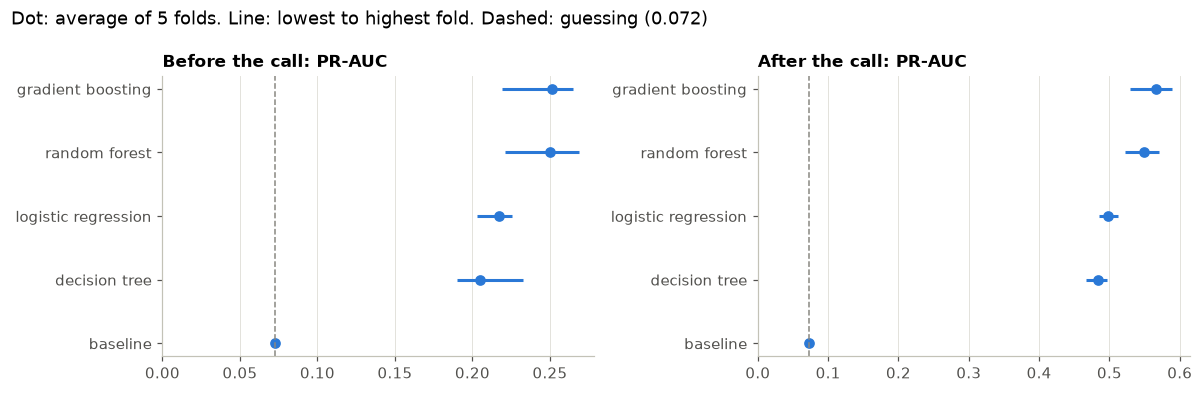

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, stage in zip(axes, STAGES, strict=True):
    folds = pd.DataFrame({name: frame[MAIN_METRIC] for name, frame in scores[stage].items()})
    folds = folds[folds.mean().sort_values(ascending=False).index]
    rows = np.arange(folds.shape[1])
    ax.hlines(rows, folds.min(), folds.max(), color=BLUE, linewidth=2)
    ax.plot(folds.mean(), rows, "o", color=BLUE, markersize=6)
    ax.axvline(y.mean(), color=MUTED, linestyle="--", linewidth=1)
    ax.set_yticks(rows, folds.columns.str.replace("_", " "))
    ax.invert_yaxis()
    ax.set_xlim(left=0)
    ax.grid(axis="y", visible=False)
    ax.set_title(f"{STAGE_NAMES[stage]}: PR-AUC", loc="left")
fig.suptitle(
    "Dot: average of 5 folds. Line: lowest to highest fold. Dashed: guessing (0.072)",
    x=0.01,
    ha="left",
)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "model_comparison.png")

**Findings:**

- **Before the call**, gradient boosting (0.251) and random forest (0.250) lead, about 3.5× the
  0.072 of guessing. Logistic regression (0.217) and the decision tree (0.205) follow.
- **After the call** the same order holds at a much higher level: gradient boosting 0.567, random
  forest 0.549, logistic regression 0.498, decision tree 0.484. Knowing how long the
  conversation lasted makes buyers far easier to spot.
- **Accuracy hides it again.** Before the call, every helper sits at about 92.8%, the same as
  always saying "no", because at the default cut-off of 0.5 they say "yes" to almost nobody
  (recall 2–7%). Section 3 fixes the cut-off.

## 2. Is the winner really better, or just lucky?

The corrected t-test (Step 6) compares the leader's 5 fold scores with each other helper's.
A p-value below 0.05 means the gap is very unlikely to be luck.

In [5]:
rows = []
for stage in STAGES:
    leader = summarize(scores[stage]).index[0]
    for other in scores[stage]:
        if other == leader:
            continue
        gain, p_value = corrected_ttest(
            scores[stage][leader][MAIN_METRIC], scores[stage][other][MAIN_METRIC]
        )
        rows.append(
            {
                "stage": stage,
                "leader": leader,
                "compared with": other,
                "PR-AUC gain": gain,
                "p_value": p_value,
            }
        )
pd.DataFrame(rows)

,stage,leader,compared with,PR-AUC gain,p_value
0,pre_call,gradient_boosting,baseline,0.179,1.343e-04
1,pre_call,gradient_boosting,logistic_regression,0.034,8.285e-03
2,pre_call,gradient_boosting,decision_tree,0.047,2.148e-02
3,pre_call,gradient_boosting,random_forest,0.001,8.434e-01
4,post_call,gradient_boosting,baseline,0.495,8.891e-06
5,post_call,gradient_boosting,logistic_regression,0.069,1.507e-02
6,post_call,gradient_boosting,decision_tree,0.083,1.263e-03
7,post_call,gradient_boosting,random_forest,0.018,1.756e-01


**Decision: gradient boosting for both stages.**

- **Random forest is a tie** (p = 0.84 before the call, 0.18 after): the gap could be luck. Between
  two equals we take the one that trains **4–5× faster** (see `seconds`) and is smaller to
  store, which matters when the model is retrained every campaign.
- **The simpler helpers are really worse** (p ≤ 0.02): choosing logistic regression or a single
  tree for readability would cost real buyers. Notebook 03 explains the chosen model instead,
  with importance and partial-dependence charts.

`config.py` records this choice in `FINAL_MODEL`, so the train command (Step 10) uses the same
model.

In [6]:
FINAL_MODEL

{'pre_call': 'gradient_boosting', 'post_call': 'gradient_boosting'}

## 3. Choosing the yes/no cut-off

The model gives every customer a chance of buying. To say "call" or "don't call" we need a
**cut-off**. The default 0.5 fails here: hardly anyone reaches a 50% chance when only 7% buy.

`with_threshold` lets the model learn its own cut-off, the one with the best **F1** (a balance of
finding buyers and not wasting calls), using only its training folds. The test folds still judge
it, so the scores stay honest. This cell takes about 2 minutes.

In [7]:
with_cutoff = {
    stage: cv_scores(
        with_threshold(candidates[FINAL_MODEL[stage]].tuned(features)), df[features], y
    )
    for stage, features in STAGES.items()
}
pd.concat(
    {
        (STAGE_NAMES[stage], cutoff): frame[["accuracy", "precision", "recall", "f1"]].mean()
        for stage in STAGES
        for cutoff, frame in [
            ("0.5", scores[stage][FINAL_MODEL[stage]]),
            ("learned", with_cutoff[stage]),
        ]
    },
    axis=1,
).T

accuracy  precision  recall     f1
Before the call 0.5         0.928      0.513   0.036  0.067
                learned     0.911      0.366   0.295  0.325
After the call  0.5         0.940      0.628   0.413  0.498
                learned     0.927      0.499   0.729  0.591

In [8]:
for stage in STAGES:
    accuracy = with_cutoff[stage]["accuracy"]
    print(
        f"{STAGE_NAMES[stage]}: 5-fold average accuracy {accuracy.mean():.1%} "
        f"(lowest fold {accuracy.min():.1%}), brief's target 81%"
    )

Before the call: 5-fold average accuracy 91.1% (lowest fold 90.5%), brief's target 81%
After the call: 5-fold average accuracy 92.7% (lowest fold 92.2%), brief's target 81%


**Findings:**

- **Before the call**, with the learned cut-off, **36.6%** of calls end in a sale (vs 7.2% when
  calling at random) and **29.5%** of all buyers are found. Accuracy: **91.1%**.
- **After the call**, **49.9%** of callbacks succeed and **72.9%** of buyers are found. Accuracy:
  **92.7%**.
- **The brief's target is met** in every fold for both models. Remember, though, that always
  answering "no" also meets it (92.8%): the precision and recall above are the real evidence.
- F1 is a sensible default when the cost of a call and the value of a sale are unknown. If the
  bank knows its call capacity, the gains table below shows what any other cut-off achieves.

## 4. Gains: what the call list achieves

Every customer gets a score from a model that never saw them (out-of-fold). Sorting the list from
the highest score down answers the planning question: *"if we call the top X%, how many buyers
do we reach, and how many calls succeed?"*

In [9]:
ranking = {
    stage: out_of_fold_scores(candidates[FINAL_MODEL[stage]].tuned(features), df[features], y)
    for stage, features in STAGES.items()
}
gains = {stage: gains_table(y, ranking[stage]) for stage in STAGES}
gains["pre_call"]

,share_called,customers_called,buyers_found,gains,success_rate,lift
0,0.1,4000,1065,0.368,0.266,3.677
1,0.2,8000,1405,0.485,0.176,2.426
2,0.3,12000,1709,0.590,0.142,1.967
3,0.4,16000,1941,0.670,0.121,1.676
4,0.5,20000,2168,0.749,0.108,1.497
5,0.6,24000,2368,0.818,0.099,1.363
6,0.7,28000,2543,0.878,0.091,1.254
7,0.8,32000,2688,0.928,0.084,1.160
8,0.9,36000,2816,0.972,0.078,1.080
9,1.0,40000,2896,1.000,0.072,1.000


In [10]:
gains["post_call"]

,share_called,customers_called,buyers_found,gains,success_rate,lift
0,0.1,4000,2035,0.703,0.509,7.027
1,0.2,8000,2711,0.936,0.339,4.681
2,0.3,12000,2844,0.982,0.237,3.273
3,0.4,16000,2872,0.992,0.179,2.479
4,0.5,20000,2884,0.996,0.144,1.992
5,0.6,24000,2887,0.997,0.120,1.661
6,0.7,28000,2892,0.999,0.103,1.427
7,0.8,32000,2893,0.999,0.090,1.249
8,0.9,36000,2894,0.999,0.080,1.110
9,1.0,40000,2896,1.000,0.072,1.000


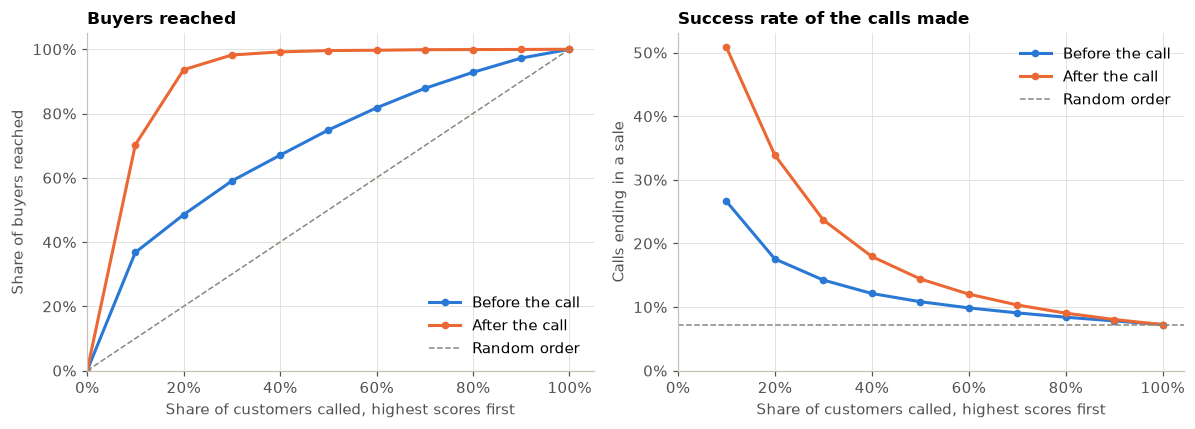

In [11]:
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4))
for stage, color in [("pre_call", BLUE), ("post_call", ORANGE)]:
    table = gains[stage]
    left.plot(
        [0, *table["share_called"]],
        [0, *table["gains"]],
        "-o",
        color=color,
        linewidth=2,
        markersize=4,
        label=STAGE_NAMES[stage],
    )
    right.plot(
        table["share_called"],
        table["success_rate"],
        "-o",
        color=color,
        linewidth=2,
        markersize=4,
        label=STAGE_NAMES[stage],
    )
left.plot([0, 1], [0, 1], "--", color=MUTED, linewidth=1, label="Random order")
right.axhline(y.mean(), color=MUTED, linestyle="--", linewidth=1, label="Random order")
left.set(xlabel="Share of customers called, highest scores first", ylabel="Share of buyers reached")
right.set(xlabel="Share of customers called, highest scores first", ylabel="Calls ending in a sale")
left.set_title("Buyers reached", loc="left")
right.set_title("Success rate of the calls made", loc="left")
for ax in (left, right):
    ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.set_xlim(left=0)
    ax.set_ylim(bottom=0)
    ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "gains.png")

**Findings:**

- **Before the call:** calling the top **10%** of the list reaches **37%** of all buyers, and
  **26.6%** of those calls succeed: **3.7×** better than random order. The top 20% reaches 49%,
  and half the list reaches 75%.
- **After the call:** the top **10%** holds **70%** of the buyers at a **51%** success rate (7×), and
  the top 20% holds 94%. Callbacks can be focused on very few customers.

## 5. Time check: does it still work on later months?

Shuffled folds mix all months, so the model always trains on some customers from the same period
it is tested on. The bank will use it on **future** campaigns. Here the model trains on the first
80% of rows (earlier months) and is tested on the last 20% (later months). We also try it without
`month` and `day`, to see whether those calendar columns mislead the model about the future.

In [12]:
((train, test),) = time_ordered_split(len(df))
print(f"Train: first {len(train):,} rows. Test: last {len(test):,} rows.")
print(f"Buyers in the test rows: {y.iloc[test].mean():.1%}")

rows = {}
for stage, features in STAGES.items():
    without_calendar = [col for col in features if col not in ("month", "day")]
    for label, columns in [("all columns", features), ("without month and day", without_calendar)]:
        model = candidates[FINAL_MODEL[stage]].tuned(columns)
        model.fit(df[columns].iloc[train], y.iloc[train])
        proba = model.predict_proba(df[columns].iloc[test])[:, 1]
        top_tenth = gains_table(y.iloc[test], proba).iloc[0]
        rows[(STAGE_NAMES[stage], label)] = {
            "roc_auc": roc_auc_score(y.iloc[test], proba),
            "average_precision": average_precision_score(y.iloc[test], proba),
            "top 10% success rate": top_tenth["success_rate"],
            "top 10% lift": top_tenth["lift"],
        }
pd.DataFrame(rows).T

Train: first 32,000 rows. Test: last 8,000 rows.
Buyers in the test rows: 12.5%


roc_auc  average_precision  \
Before the call all columns              0.635              0.218   
                without month and day    0.629              0.195   
After the call  all columns              0.856              0.473   
                without month and day    0.862              0.459   

                                       top 10% success rate  top 10% lift  
Before the call all columns                           0.260          2.08  
                without month and day                 0.241          1.93  
After the call  all columns                           0.540          4.32  
                without month and day                 0.514          4.11

**Findings:**

- **Before the call, the model still helps on later months, but less.** In the later months
  12.5% of customers buy. The top 10% of the model's list buys at **26%**, a **2.1×** lift,
  against 3.7× in the shuffled folds. ROC-AUC drops from 0.72 to 0.64.
- **After the call**, it stays strong: ROC-AUC 0.86 (0.95 shuffled), and the top 10% buys at
  **54%** (4.3× lift).
- **Dropping `month` and `day` does not help** on later months (before the call, PR-AUC falls from
  0.218 to 0.195), so they stay in.

**Decision:** the 5-fold numbers answer the brief, but the client should expect the **time-check
numbers on a new campaign**: about 2× more sales per call from the top tenth of the list. The
model should be retrained on each new campaign's results, which is what the train command
(Step 10) is for.

## 6. Summary

| | Before the call | After the call |
| --- | --- | --- |
| Chosen helper | gradient boosting | gradient boosting |
| **5-fold accuracy (brief's target: 81%)** | **91.1%** | **92.7%** |
| PR-AUC (guessing: 0.072) | 0.251 | 0.567 |
| ROC-AUC (guessing: 0.50) | 0.72 | 0.95 |
| Calls ending in a sale, at the learned cut-off | 36.6% | 49.9% |
| Buyers found, at the learned cut-off | 29.5% | 72.9% |
| Calling the top 10% of the list | 37% of buyers, 26.6% success, 3.7× | 70% of buyers, 51% success, 7× |
| Later months, top 10% of the list | 26% success, 2.1× | 54% success, 4.3× |

| Decision | Chosen | Instead of | Why |
| --- | --- | --- | --- |
| Model | Gradient boosting | Random forest | Tied (p = 0.84 / 0.18); 4–5× faster to train |
| Model | Gradient boosting | Logistic regression, decision tree | Significantly better (p ≤ 0.02) |
| Cut-off | Learned per model (best F1) | 0.5 | 0.5 finds only 3.6% of buyers before the call |
| Calendar columns | Kept | Dropped | Dropping them does not help on later months |
| Reported performance | 5-fold numbers plus the time check | 5-fold only | Future campaigns look more like the time check |

### Where the predictions are used in real life

**Before the call:**

- **The daily call list:** customers sorted by score, agents start at the top (section 4: the top
  10% of the list holds 37% of the buyers).
- **Sizing the campaign:** the sum of the probabilities is the expected number of sales, so the
  bank can decide how many calls are worth paying for.
- **Choosing the channel:** a call for high scores, a cheaper letter or e-mail for low ones.
- **Matching agents to leads:** the most experienced agents take the highest scores.
- **Limiting repeat calls:** the yes rate falls with every extra call (notebook 01), so stopping
  after a few attempts saves effort and spares customers unwanted calls.

**After the call:** a **callback queue** (who to follow up first, and whose file to close), and
warm leads handed to a senior adviser.

**Over time:** compare predicted with actual sales after each campaign, and retrain with the
train command when they drift apart.